In [1]:
import pandas as pd

base = "../data/raw"
columns = ["engine_id", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]

test = pd.read_csv(base +  "/test_FD001.txt", sep=r"\s+", header=None, names=columns)
rul_true = pd.read_csv(base + "/RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])

print(test.shape, rul_true.shape)

(13096, 26) (100, 1)


In [2]:
last = test.groupby("engine_id")["cycle"].max()
print(last.head())
print(last.describe())

engine_id
1     31
2     49
3    126
4    106
5     98
Name: cycle, dtype: int64
count    100.000000
mean     130.960000
std       53.593479
min       31.000000
25%       88.750000
50%      133.500000
75%      164.250000
max      303.000000
Name: cycle, dtype: float64


In [3]:
flat_cols = ["s1", "s5", "s6", "s10", "s16", "s18", "s19", "op3"]
test_df = test.drop(columns=flat_cols)


In [4]:
sensors = ['s2','s3','s4','s7','s8','s9','s11','s12','s13','s14','s15','s17','s20','s21']   # the 14 sensors left after dropping flat_cols

for s in sensors:
    test_df[f"{s}_rollmean"] = test_df.groupby('engine_id')[s].transform(
        lambda x: x.rolling(window=5, min_periods=1).mean()
    )
    test_df[f"{s}_rollstd"] = test_df.groupby('engine_id')[s].transform(
        lambda x: x.rolling(window=5, min_periods=1).std().fillna(0)
    )

print(test_df.shape)

(13096, 46)


In [5]:
path = "../data/raw/train_FD001.txt"

train_df = pd.read_csv(path, sep=r"\s+", header=None, names=columns)

flat_cols = ["s1", "s5", "s6", "s10", "s16", "s18", "s19", "op3"]
train_df = train_df.drop(columns=flat_cols)

sensors = ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']   # the 14 remaining sensors, in number order: "s2", "s3", ...

for s in sensors:
    train_df[f"{s}_rollmean"] = train_df.groupby("engine_id")[s].transform(
        lambda x: x.rolling(window=5, min_periods=1).mean()
    )
    train_df[f"{s}_rollstd"] = train_df.groupby("engine_id")[s].transform(
        lambda x: x.rolling(window=5, min_periods=1).std().fillna(0)
    )

print(train_df.shape)
print(list(train_df.columns) == list(test_df.columns))


(20631, 46)
True


In [6]:
from sklearn.preprocessing import MinMaxScaler

feature_cols = [c for c in train_df.columns if c not in ["engine_id", "cycle"]]

scaler = MinMaxScaler()
scaler.fit(train_df[feature_cols])
test_df[feature_cols] = scaler.transform(test_df[feature_cols])

print(len(feature_cols))
print(test_df[feature_cols].describe().loc[["min", "max"]])

44
          op1       op2        s2        s3        s4        s7        s8  \
min  0.028736  0.000000 -0.024096 -0.043601  0.036124  0.165862 -0.015152   
max  0.948276  1.083333  0.930723  0.795945  0.862762  0.964573  0.606061   

           s9       s11       s12  ...  s14_rollmean  s14_rollstd  \
min  0.012564 -0.029762  0.147122  ...      0.045834     0.000000   
max  0.598133  0.839286  1.081023  ...      0.629380     1.073518   

     s15_rollmean  s15_rollstd  s17_rollmean  s17_rollstd  s20_rollmean  \
min      0.077786     0.000000     -0.131579     0.000000      0.127119   
max      0.888177     0.765591      0.815789     0.844097      0.957627   

     s20_rollstd  s21_rollmean  s21_rollstd  
min     0.000000      0.111404     0.000000  
max     1.152174      1.017574     0.855295  

[2 rows x 44 columns]


In [7]:
import pickle

model_path = "../outputs/models/rf_fd001_capped.pkl"

with open(model_path, "rb") as f:
    model = pickle.load(f)

print("loaded", type(model))

loaded <class 'sklearn.ensemble._forest.RandomForestRegressor'>


In [8]:
# F1: honest score
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

last_rows = test_df.groupby("engine_id").tail(1)          # last row of each engine
X_last = last_rows[feature_cols]

with open(model_path, "rb") as f:
    model = pickle.load(f)

pred = model.predict(X_last)
y_true = rul_true["RUL"].clip(upper=125)                   # same cap as training

rmse = np.sqrt(mean_squared_error(y_true, pred))
mae = mean_absolute_error(y_true, pred)
r2 = r2_score(y_true, pred)
print(X_last.shape, round(rmse, 2), round(mae, 2), round(r2, 3))

(100, 44) 17.91 12.81 0.8


In [9]:
out = pd.DataFrame({
    "engine_id": last_rows["engine_id"].values,
    "last_cycle": last_rows["cycle"].values,
    "rul_true": y_true.values,
    "rul_pred": pred,
})
out["error"] = out["rul_pred"] - out["rul_true"]
out["abs_error"] = out["error"].abs()
out.to_csv("../data/processed/fd001_test_predictions.csv", index=False)
print(out.shape)
out.sort_values("abs_error", ascending=False).head(10)

(100, 6)


,engine_id,last_cycle,rul_true,rul_pred,error,abs_error
78,79,101,63,121.625,58.625,58.625
36,37,121,21,70.575,49.575,49.575
26,27,140,66,111.660,45.660,45.660
92,93,244,85,40.110,-44.890,44.890
44,45,152,114,69.710,-44.290,44.290
11,12,217,124,83.595,-40.405,40.405
17,18,133,28,64.645,36.645,36.645
42,43,172,59,90.100,31.100,31.100
14,15,76,83,113.695,30.695,30.695
40,41,123,18,47.995,29.995,29.995


In [10]:
# F1 check: how many of the 100 test engines sit at the RUL cap of 125
print((out["rul_true"] == 125).sum())

11


In [11]:
print(out["error"].mean())                         # average signed error: bias
print((out["error"] > 0).mean())                   # share of engines over-predicted

out["band_true"] = pd.cut(out["rul_true"], bins=[-1, 30, 70, 200],
                          labels=["CRITICAL", "WARNING", "HEALTHY"])
print(out.groupby("band_true", observed=True)["abs_error"].mean())

3.2816
0.58


band_true
CRITICAL     9.262400
WARNING     16.660588
HEALTHY     13.217759
Name: abs_error, dtype: float64


In [12]:
# F3: error by band
print(out.groupby("band_true", observed=True)["error"].agg(["count", "mean"]))

           count       mean
band_true                  
CRITICAL      25   7.906400
WARNING       17  10.961176
HEALTHY       58  -0.962759


In [13]:
#F2:Band Table
out["band_pred"] = pd.cut(out["rul_pred"], bins=[-1, 30, 70, 200], labels=["CRITICAL", "WARNING", "HEALTHY"])
pd.crosstab(out["band_true"], out["band_pred"])

band_pred,CRITICAL,WARNING,HEALTHY
band_true,,,
CRITICAL,17,7,1
WARNING,1,11,5
HEALTHY,0,3,55


In [14]:
# F2 check B
print((out["rul_true"] < 30).sum())
print(((out["rul_true"] < 30) & (out["rul_pred"] < 30)).sum())
print(((out["rul_true"] < 30) & (out["rul_pred"] > 70)).sum())

25
17
1


In [15]:
# F2 check C
out[out["rul_true"] < 30].sort_values("rul_pred")

,engine_id,last_cycle,rul_true,rul_pred,error,abs_error,band_true,band_pred
33,34,203,7,5.165,-1.835,1.835,CRITICAL,CRITICAL
80,81,213,8,6.155,-1.845,1.845,CRITICAL,CRITICAL
34,35,198,11,9.055,-1.945,1.945,CRITICAL,CRITICAL
81,82,162,9,11.265,2.265,2.265,CRITICAL,CRITICAL
67,68,187,8,12.015,4.015,4.015,CRITICAL,CRITICAL
75,76,205,10,12.580,2.580,2.580,CRITICAL,CRITICAL
55,56,136,15,12.585,-2.415,2.415,CRITICAL,CRITICAL
30,31,196,8,13.345,5.345,5.345,CRITICAL,CRITICAL
65,66,147,14,16.610,2.610,2.610,CRITICAL,CRITICAL
91,92,150,20,16.865,-3.135,3.135,CRITICAL,CRITICAL


In [16]:
# F4: where the error sits
worst10 = out.sort_values("abs_error", ascending=False).head(10)
share = (worst10["error"] ** 2).sum() / (out["error"] ** 2).sum()
print(round(share * 100))
worst10.head(1)

55


,engine_id,last_cycle,rul_true,rul_pred,error,abs_error,band_true,band_pred
78,79,101,63,121.625,58.625,58.625,WARNING,HEALTHY


In [17]:
# F4: feature importance
imp = pd.read_csv("../data/processed/feature_importance.csv")
imp.head(5)

,Sensor,importance
0,s4_rollmean,59.6
1,s11_ rollmean,10.1
2,s9_rollmean,9.4
3,s14_rollmean,1.5
4,s15_rollmean,1.4


In [18]:
# F5: per-cycle table
per_cycle = test_df[["engine_id", "cycle"]].copy()

# 1. the last cycle of each engine, copied onto every row of that engine
per_cycle["last_cycle"] = per_cycle.groupby("engine_id")["cycle"].transform("max")

# 2. RUL after the last cycle, one value per engine (this line is given)
rul_final = pd.Series(rul_true["RUL"].values, index=range(1, 101))
per_cycle["rul_final"] = per_cycle["engine_id"].map(rul_final)

# 3. the formula from before, then the cap
per_cycle["rul_true"] = (per_cycle["rul_final"] + per_cycle["last_cycle"] - per_cycle["cycle"]).clip(upper=125)

# check: engine 1 at cycle 20 should show 123
print(per_cycle[(per_cycle["engine_id"] == 1) & (per_cycle["cycle"] == 20)])

    engine_id  cycle  last_cycle  rul_final  rul_true
19          1     20          31        112       123


In [19]:
print(per_cycle.shape)
print(per_cycle.columns.tolist())

(13096, 5)
['engine_id', 'cycle', 'last_cycle', 'rul_final', 'rul_true']


In [20]:
# F5: predictions on every row
X_all = test_df[feature_cols]
per_cycle["rul_pred"] = model.predict(X_all)
per_cycle["error"] = per_cycle["rul_pred"] - per_cycle["rul_true"]
print(per_cycle.shape)
per_cycle.head()

(13096, 7)


,engine_id,cycle,last_cycle,rul_final,rul_true,rul_pred,error
0,1,1,31,112,125,118.540,-6.460
1,1,2,31,112,125,111.235,-13.765
2,1,3,31,112,125,112.345,-12.655
3,1,4,31,112,125,115.675,-9.325
4,1,5,31,112,125,119.715,-5.285


In [21]:
last_pc = per_cycle.groupby("engine_id").tail(1)
print((last_pc["rul_true"].values == out["rul_true"].values).all())
print(np.allclose(last_pc["rul_pred"].values, out["rul_pred"].values))

True
True


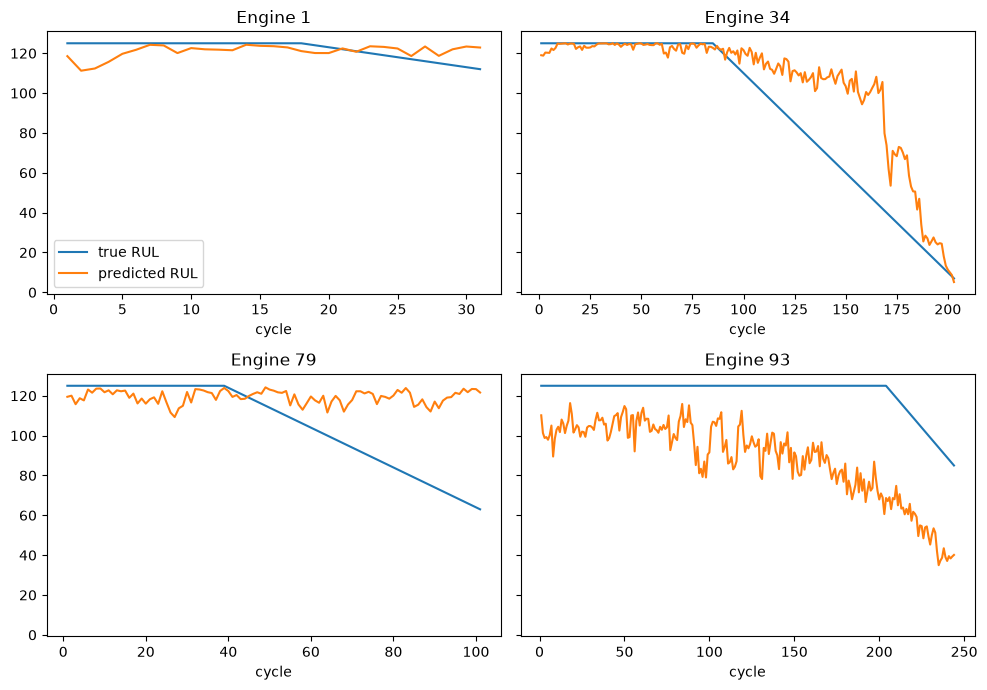

In [22]:
import matplotlib.pyplot as plt

engines = [1, 34, 79, 93]   # a short one, a near-failure hit, the worst miss, a long one

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharey=True)
for ax, eng in zip(axes.flat, engines):
    d = per_cycle[per_cycle["engine_id"] == eng]
    ax.plot(d["cycle"], d["rul_true"], label="true RUL")
    ax.plot(d["cycle"], d["rul_pred"], label="predicted RUL")
    ax.set_title(f"Engine {eng}")
    ax.set_xlabel("cycle")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("../data/processed/trend_check.png")
plt.show()

In [23]:
# F4: export top-5 importance
top5 = imp.head(5).copy()
top5["Sensor"] = top5["Sensor"].str.replace(" ", "")
top5.to_csv("../data/processed/feature_importance_top5.csv", index=False)
top5

,Sensor,importance
0,s4_rollmean,59.6
1,s11_rollmean,10.1
2,s9_rollmean,9.4
3,s14_rollmean,1.5
4,s15_rollmean,1.4


In [24]:
# F5: export per-cycle table
cols = ["engine_id", "cycle", "rul_true", "rul_pred"]
per_cycle[cols].to_csv("../data/processed/fd001_test_by_cycle.csv", index=False)
print(per_cycle[cols].shape)

(13096, 4)
